<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_06_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Exact path to your processed folder
path = "/content/drive/MyDrive/DemandLens/Data/"
OUT_PROCESSED = path + "processed/"

In [ ]:
# Load 7-Day Horizon Train & Validation Datasets
train_7  = pd.read_parquet(f"{OUT_PROCESSED}ca1_h7_train.parquet")
val_7    = pd.read_parquet(f"{OUT_PROCESSED}ca1_h7_val.parquet")

In [ ]:
#  Load 28-Day Horizon Train & Validation Datasets
train_28 = pd.read_parquet(f"{OUT_PROCESSED}ca1_h28_train.parquet")
val_28   = pd.read_parquet(f"{OUT_PROCESSED}ca1_h28_val.parquet")

In [ ]:
train_7.shape, val_7.shape

((4552041, 26), (85372, 26))

In [ ]:
train_28.shape, val_28.shape

((4424067, 26), (85359, 26))

In [ ]:
pd.set_option("display.max_columns", None)

In [ ]:
train_7.head()

,item_id,store_id,date,sales,lag_7,rolling_mean_7,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-02-09,0,4.0,1.600000,5,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-02-10,3,2.0,1.666667,6,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-02-11,1,0.0,1.428571,7,2,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-02-12,3,2.0,1.285714,1,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-02-13,0,0.0,1.285714,2,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [ ]:
drop_cols = ["item_id", "store_id", "date", "sales"]

In [ ]:
# 7-Day Horizon
X_train_7 = train_7.drop(columns=drop_cols)
y_train_7 = train_7["sales"]
X_val_7   = val_7.drop(columns=drop_cols)
y_val_7   = val_7["sales"]

In [ ]:
# 28-Day Horizon
X_train_28 = train_28.drop(columns=drop_cols)
y_train_28 = train_28["sales"]
X_val_28   = val_28.drop(columns=drop_cols)
y_val_28   = val_28["sales"]

In [ ]:
X_train_7.shape, y_train_7.shape, X_val_7.shape, y_val_7.shape

((4552041, 22), (4552041,), (85372, 22), (85372,))

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [ ]:
# Evaluation function (identical to rest algorithms for a 100% fair comparison)
def evaluate_forecast(y_true, y_pred):
    y_pred_clipped = np.clip(y_pred, 0, None)
    wape = np.sum(np.abs(y_true - y_pred_clipped)) / np.sum(np.abs(y_true)) * 100
    mae  = mean_absolute_error(y_true, y_pred_clipped)
    rmse = root_mean_squared_error(y_true, y_pred_clipped)
    return {"WAPE (%)": round(wape, 2), "MAE": round(mae, 4), "RMSE": round(rmse, 4)}

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
depths = [10, 12, 15]
results_7, results_28 = [], []

### Random Forest: Training Speed & RAM Optimization

Our dataset contains approximately **4.55 million rows**. Training a Random Forest on the complete dataset can be computationally expensive and may consume a significant amount of RAM in Google Colab.

To make training more manageable, we will use the following parameters:

**1. `n_jobs=-1`**
- Uses all available CPU cores.
- Allows multiple trees to be trained in parallel, reducing training time.

**2. `max_samples=0.25`**
- Each tree uses a random sample of 25% of the training data.
- For 4.55 million rows, this is approximately 1.14 million rows per tree.
- Reduces the amount of data processed by each tree and can improve training speed.

**3. `min_samples_leaf=50`**
- Requires at least 50 samples in each leaf node.
- Prevents trees from creating very small leaves.
- Helps reduce overfitting and unnecessary tree complexity.

**4. `max_features="sqrt"`**
- Considers the square root of the total number of features when searching for the best split.
- Reduces the number of features evaluated at each split.
- Helps reduce computation and increases diversity among trees.

**Note:** These settings aim to make Random Forest training more manageable. Actual training time and RAM usage depend on available resources, dataset size, number of features, and tree complexity.

In [ ]:
for d in depths:
    # 7-Day Random Forest
    rf7 = RandomForestRegressor(
        n_estimators=40,
        max_depth=d,
        min_samples_leaf=50,
        max_features=0.7,
        max_samples=0.25,
        n_jobs=-1,
        random_state=42
    )
    rf7.fit(X_train_7, y_train_7)
    val_m7 = evaluate_forecast(y_val_7, rf7.predict(X_val_7))
    results_7.append({"max_depth": d, **val_m7})
    print(f"7-Day  RF (depth={d}) -> {val_m7}")

    # 28-Day Random Forest
    rf28 = RandomForestRegressor(
        n_estimators=40,
        max_depth=d,
        min_samples_leaf=50,
        max_features=0.7,
        max_samples=0.25,
        n_jobs=-1,
        random_state=42
    )
    rf28.fit(X_train_28, y_train_28)
    val_m28 = evaluate_forecast(y_val_28, rf28.predict(X_val_28))
    results_28.append({"max_depth": d, **val_m28})
    print(f"28-Day RF (depth={d}) -> {val_m28}\n")

7-Day  RF (depth=10) -> {'WAPE (%)': np.float64(75.08), 'MAE': 1.1253, 'RMSE': 2.1744}
28-Day RF (depth=10) -> {'WAPE (%)': np.float64(76.33), 'MAE': 1.144, 'RMSE': 2.208}

7-Day  RF (depth=12) -> {'WAPE (%)': np.float64(74.9), 'MAE': 1.1226, 'RMSE': 2.1728}
28-Day RF (depth=12) -> {'WAPE (%)': np.float64(76.47), 'MAE': 1.1461, 'RMSE': 2.21}

7-Day  RF (depth=15) -> {'WAPE (%)': np.float64(74.84), 'MAE': 1.1217, 'RMSE': 2.1719}
28-Day RF (depth=15) -> {'WAPE (%)': np.float64(76.41), 'MAE': 1.1453, 'RMSE': 2.2119}



In [ ]:
df_rf_7  = pd.DataFrame(results_7).sort_values("WAPE (%)")
df_rf_7

,max_depth,WAPE (%),MAE,RMSE
2,15,74.84,1.1217,2.1719
1,12,74.90,1.1226,2.1728
0,10,75.08,1.1253,2.1744


In [ ]:
df_rf_28 = pd.DataFrame(results_28).sort_values("WAPE (%)")
df_rf_28

,max_depth,WAPE (%),MAE,RMSE
0,10,76.33,1.1440,2.2080
2,15,76.41,1.1453,2.2119
1,12,76.47,1.1461,2.2100


In [ ]:
print(df_rf_7.to_string(index=False))

 max_depth  WAPE (%)    MAE   RMSE
        15     74.84 1.1217 2.1719
        12     74.90 1.1226 2.1728
        10     75.08 1.1253 2.1744


In [ ]:
print(df_rf_28.to_string(index=False))

 max_depth  WAPE (%)    MAE   RMSE
        10     76.33 1.1440 2.2080
        15     76.41 1.1453 2.2119
        12     76.47 1.1461 2.2100


In [ ]:
# 1. Fit Final 100-Tree Models with Winning Depths
best_rf_7 = RandomForestRegressor(
    n_estimators=100, max_depth=15, min_samples_leaf=50,
    max_features=0.7, max_samples=0.25, n_jobs=-1, random_state=42
).fit(X_train_7, y_train_7)

best_rf_28 = RandomForestRegressor(
    n_estimators=100, max_depth=10, min_samples_leaf=50,
    max_features=0.7, max_samples=0.25, n_jobs=-1, random_state=42
).fit(X_train_28, y_train_28)

In [ ]:
print("Final 7-Day  Val (100 trees):", evaluate_forecast(y_val_7,  best_rf_7.predict(X_val_7)))
print("Final 28-Day Val (100 trees):", evaluate_forecast(y_val_28, best_rf_28.predict(X_val_28)))

Final 7-Day  Val (100 trees): {'WAPE (%)': np.float64(74.83), 'MAE': 1.1215, 'RMSE': 2.1708}
Final 28-Day Val (100 trees): {'WAPE (%)': np.float64(76.3), 'MAE': 1.1435, 'RMSE': 2.2054}


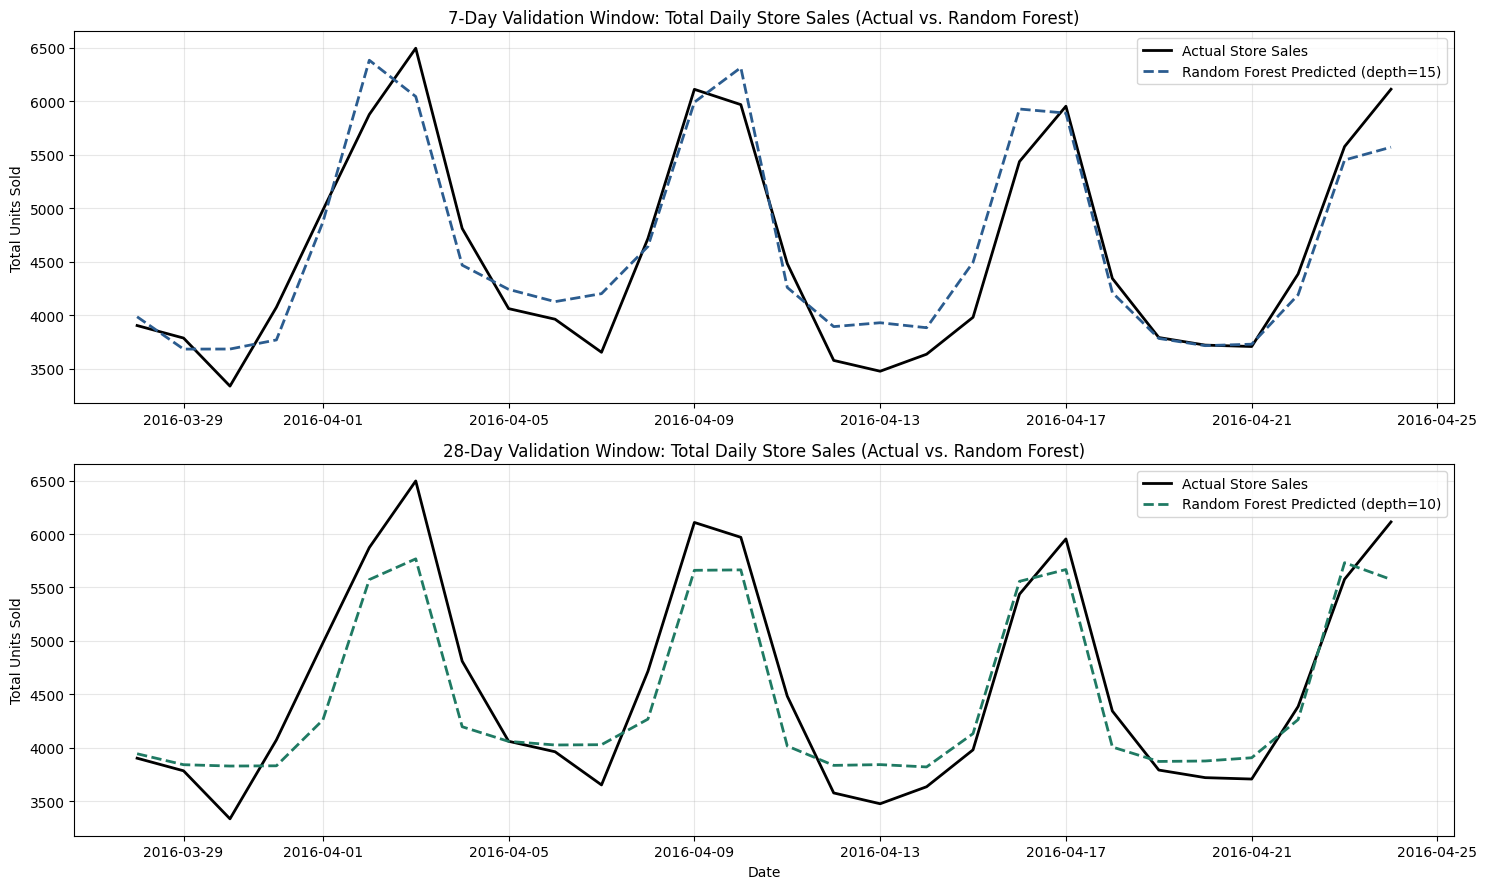

In [ ]:
# 2. Plot Store-Level Daily Aggregated Actual vs. Predicted (7-Day & 28-Day)
val_plot_7 = val_7[["date", "sales"]].copy()
val_plot_7["predicted"] = np.clip(best_rf_7.predict(X_val_7), 0, None)
daily_agg_7 = val_plot_7.groupby("date")[["sales", "predicted"]].sum().reset_index()

val_plot_28 = val_28[["date", "sales"]].copy()
val_plot_28["predicted"] = np.clip(best_rf_28.predict(X_val_28), 0, None)
daily_agg_28 = val_plot_28.groupby("date")[["sales", "predicted"]].sum().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(daily_agg_7["date"], daily_agg_7["sales"], label="Actual Store Sales", color="black", linewidth=2)
axes[0].plot(daily_agg_7["date"], daily_agg_7["predicted"], label="Random Forest Predicted (depth=15)", color="#2b5c8f", linestyle="--", linewidth=2)
axes[0].set_title("7-Day Validation Window: Total Daily Store Sales (Actual vs. Random Forest)")
axes[0].set_ylabel("Total Units Sold")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(daily_agg_28["date"], daily_agg_28["sales"], label="Actual Store Sales", color="black", linewidth=2)
axes[1].plot(daily_agg_28["date"], daily_agg_28["predicted"], label="Random Forest Predicted (depth=10)", color="#1f7a63", linestyle="--", linewidth=2)
axes[1].set_title("28-Day Validation Window: Total Daily Store Sales (Actual vs. Random Forest)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Total Units Sold")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

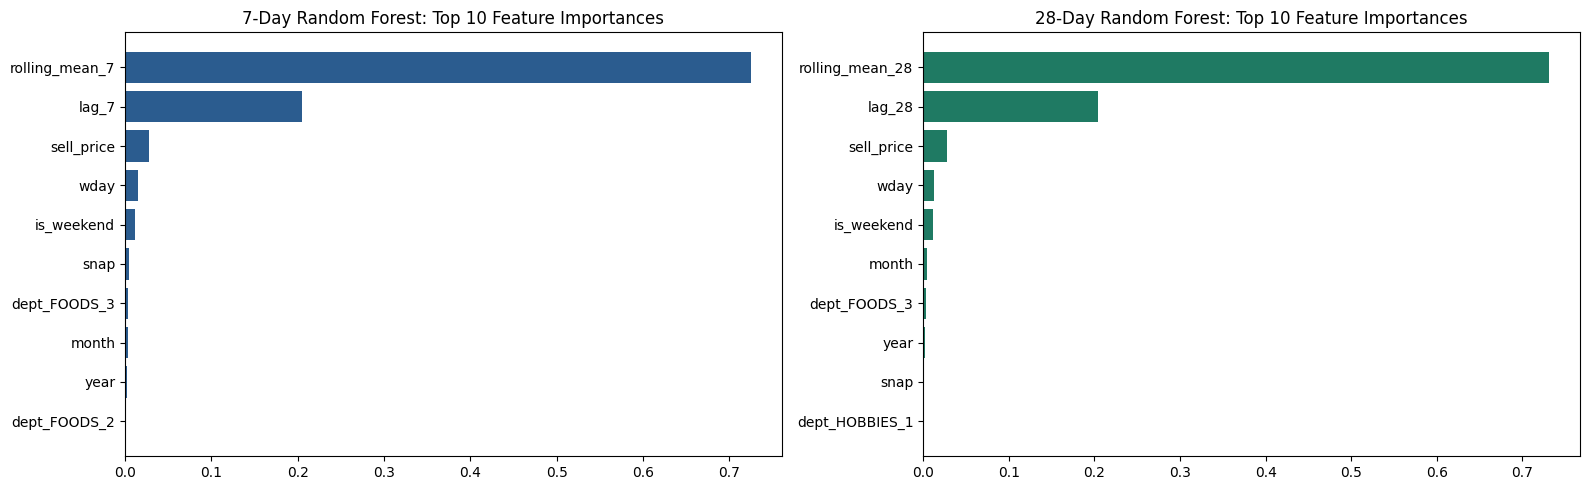

In [ ]:
# 3. Top 10 Feature Importances
imp_7  = pd.DataFrame({"Feature": X_train_7.columns,  "Importance": best_rf_7.feature_importances_}).sort_values("Importance").tail(10)
imp_28 = pd.DataFrame({"Feature": X_train_28.columns, "Importance": best_rf_28.feature_importances_}).sort_values("Importance").tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(imp_7["Feature"],  imp_7["Importance"],  color="#2b5c8f")
axes[0].set_title("7-Day Random Forest: Top 10 Feature Importances")

axes[1].barh(imp_28["Feature"], imp_28["Importance"], color="#1f7a63")
axes[1].set_title("28-Day Random Forest: Top 10 Feature Importances")

plt.tight_layout()
plt.show()